# Training and validating a ResNet/Inception emitter classifier

Day-1, chamber, cold, chirp pulses from adc0 only. Each pulse is given to a 1-D ResNet as three channels (I, Q, magnitude), normalised by its peak magnitude.

In [1]:
import torch
import numpy as np

seed = 42
generator = torch.Generator().manual_seed(seed)
np.random.seed(seed)

if torch.backends.mps.is_available():
    device = torch.device('mps')
elif torch.cuda.is_available():
    device = torch.device('cuda:0')
else:
    device = torch.device('cpu')
print(f"Using device: {device}")

Using device: cuda:0


## Load the data

In [2]:
# import sys; sys.path.append("..")     # uncomment if this notebook is not in the project root
from dataloaders.dataloader import SimplePulseDataset

ds = SimplePulseDataset(
    hdf5_dir="./data",
    load_to_memory=True,
    max_pulses_per_emitter=1000,
    adc_names=["adc0"],
    adc_mode="single",
    day_filter=["day1"],
    environment_filter=["chamber"],
    temp_filter=["cold"],
    blade_filter=None,
    waveform_filter=["chirp"],
    return_pdw=True,
)

Dataset: 12000 groups x 1 ADCs (0 unmatched, 2 below 31 dB dropped)
Loading all data to memory...
Loaded 12000 entries to memory


## Emitter classes and train/test split

In [3]:
from torch.utils.data import random_split

# Build emitter vocabulary directly from the filtered dataset
emitter_idx = {
    emitter: i
    for i, emitter in enumerate(sorted({entry["labels"]["emitter"] for entry in ds.pulse_index}))
}
idx_to_label = {v: k for k, v in emitter_idx.items()}
print(f"Emitter classes ({len(emitter_idx)}): {list(emitter_idx.keys())}")

train_size = int(0.8 * len(ds))
test_size = len(ds) - train_size
train_base, test_base = random_split(ds, [train_size, test_size], generator=generator)

Emitter classes (12): ['blade1', 'blade10', 'blade11', 'blade12', 'blade2', 'blade3', 'blade4', 'blade5', 'blade6', 'blade7', 'blade8', 'blade9']


## Training data

In [4]:
from dataloaders.dataloader import AugmentedPulseDataset
from torch.utils.data import DataLoader

train_SNRs = [30, 25, 20, 15, 10, 5, 0]
test_SNRs = [30, 25, 20, 15, 10, 5, 0]

train_dataset = AugmentedPulseDataset(
    base_dataset=train_base,
    target_snrs_db=train_SNRs,
    add_magnitude=True,
    normalise=True,
    return_pdw=False,
    mode="single",
    flatten_pulse=False
)

test_dataset = AugmentedPulseDataset(
    base_dataset=test_base,
    target_snrs_db=test_SNRs,
    add_magnitude=True,
    normalise=True,
    return_pdw=False,
    mode="single",
    flatten_pulse=False
)

train_loader = DataLoader(train_dataset, batch_size=64, shuffle=True)
test_loader = DataLoader(test_dataset, batch_size=64, shuffle=False)

## Model

In [5]:
from models.resnet import ResNet12_1D
from models.inception import Inception1D

model = ResNet12_1D(num_classes=len(emitter_idx), in_channels=3)
model = model.to(device)

## Train

In [6]:
import copy
import time
import torch.nn as nn
import torch.optim as optim
from tqdm.auto import tqdm

patience = 15
num_epochs = 50

criterion = nn.CrossEntropyLoss()
optimiser = optim.AdamW(model.parameters(), lr=0.0001, weight_decay=0.01)
scheduler = optim.lr_scheduler.CosineAnnealingLR(
    optimiser,
    T_max=num_epochs,
    eta_min=1e-5   # don't decay all the way to zero
)

best_loss = float("inf")
best_state = None
epochs_no_improve = 0

start_training = time.time()

for epoch in range(num_epochs):
    model.train()
    epoch_start = time.time()
    total_train_loss = 0.0

    # Training
    for signals, labels in tqdm(train_loader, desc=f"Epoch {epoch+1}/{num_epochs} - Training", leave=False):
        signals = signals.to(device)
        label_indices = torch.tensor(
            [emitter_idx[label] for label in labels['emitter']],
            dtype=torch.long,
            device=device,
        )
        preds = model(signals)
        train_loss = criterion(preds, label_indices)
        optimiser.zero_grad()
        train_loss.backward()
        optimiser.step()
        total_train_loss += train_loss.item()

    avg_train_loss = total_train_loss / len(train_loader)

    # Evaluation
    model.eval()
    total_test_loss = 0.0
    correct = 0
    total = 0

    with torch.no_grad():
        for signals, labels in tqdm(test_loader, desc=f"Epoch {epoch+1}/{num_epochs} - Testing", leave=False):
            signals = signals.to(device)
            label_indices = torch.tensor(
                [emitter_idx[label] for label in labels['emitter']],
                dtype=torch.long,
                device=device,
            )
            preds = model(signals)
            test_loss = criterion(preds, label_indices)
            total_test_loss += test_loss.item()
            _, predicted = torch.max(preds, 1)
            total += label_indices.size(0)
            correct += (predicted == label_indices).sum().item()

    avg_test_loss = total_test_loss / len(test_loader)
    accuracy = 100 * correct / total

    scheduler.step()

    print(f"[Epoch {epoch+1}] Train loss: {avg_train_loss:.4f} | Test loss: {avg_test_loss:.4f} | "
          f"Test accuracy: {accuracy:.2f}% | {time.time() - epoch_start:.1f}s")

    # Keep the best model (lowest test loss)
    if avg_test_loss < best_loss:
        best_loss = avg_test_loss
        best_state = copy.deepcopy(model.state_dict())
        epochs_no_improve = 0
        print(f"[Epoch {epoch+1}] Best model so far")
    else:
        epochs_no_improve += 1

    # Early stopping
    if epochs_no_improve >= patience:
        print(f"Early stopping triggered after {patience} epochs with no improvement.")
        break

print(f"Total training time: {(time.time() - start_training) / 60:.2f} minutes")

/home/ryan/anaconda3/envs/RSEI/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


[Epoch 1] Train loss: 2.0708 | Test loss: 1.9418 | Test accuracy: 23.23% | 108.3s
[Epoch 1] Best model so far


[Epoch 2] Train loss: 1.8083 | Test loss: 1.8380 | Test accuracy: 26.17% | 109.2s
[Epoch 2] Best model so far


[Epoch 3] Train loss: 1.7015 | Test loss: 2.1496 | Test accuracy: 25.02% | 107.5s


[Epoch 4] Train loss: 1.5706 | Test loss: 1.6134 | Test accuracy: 37.98% | 111.7s
[Epoch 4] Best model so far


...

[Epoch 46] Train loss: 0.8919 | Test loss: 0.9271 | Test accuracy: 66.33% | 111.9s


[Epoch 47] Train loss: 0.8889 | Test loss: 0.8947 | Test accuracy: 67.47% | 108.3s


[Epoch 48] Train loss: 0.8872 | Test loss: 0.8740 | Test accuracy: 68.76% | 107.6s


[Epoch 49] Train loss: 0.8873 | Test loss: 0.8827 | Test accuracy: 68.03% | 107.4s


[Epoch 50] Train loss: 0.8854 | Test loss: 0.8830 | Test accuracy: 68.02% | 107.6s
Total training time: 92.60 minutes
Restored the best weights (test loss 0.8692)


## Plotting helpers

In [8]:
%matplotlib inline
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay, matthews_corrcoef, f1_score

def plot_confusion_matrix(y_true, y_pred, label):
    mcc = matthews_corrcoef(y_true, y_pred)
    fone = f1_score(y_true, y_pred, average="macro")
    print(f"  [{label}] MCC: {mcc:.4f} | F1 (macro): {fone:.4f}")

    class_ids = sorted(idx_to_label.keys())
    display_labels = [idx_to_label[i] for i in class_ids]
    cm_norm = confusion_matrix(y_true, y_pred, normalize="true", labels=class_ids)

    fig, ax = plt.subplots(figsize=(10, 8))
    ConfusionMatrixDisplay(confusion_matrix=cm_norm, display_labels=display_labels).plot(
        cmap="viridis", ax=ax, xticks_rotation=45, values_format=".2f"
    )
    ax.set_title(f"ResNet Confusion Matrix — {label}", fontsize=14)
    ax.set_xlabel("Predicted Label", fontsize=13)
    ax.set_ylabel("True Label", fontsize=13)
    plt.tight_layout()
    plt.show()

    return mcc, fone


def plot_f1_vs_snr(f1_scores, snrs):
    fig, ax = plt.subplots(figsize=(10, 5))
    ax.plot(snrs, f1_scores, marker="o", color="steelblue", linewidth=2, label="ResNet")
    ax.set_xticks(snrs)
    ax.set_xlabel("SNR (dB)", fontsize=13)
    ax.set_ylabel("F1 (macro)", fontsize=13)
    ax.set_ylim(0, 1.05)
    ax.grid(True, alpha=0.3)
    ax.legend()
    ax.set_title("ResNet — F1 vs SNR", fontsize=14)
    plt.tight_layout()
    plt.show()

## Save the model

In [9]:
import os

run_name = "day1_chamber_cold_adc0_chirp_resnet"
run_dir = os.path.join("runs", run_name)
os.makedirs(run_dir, exist_ok=True)

model_path = os.path.join(run_dir, f"{run_name}_model.pth")
torch.save({"model_state_dict": model.state_dict(), "emitter_idx": emitter_idx}, model_path)
print(f"Saved model: {model_path}")

Saved model: runs/day1_chamber_cold_adc0_chirp_resnet/day1_chamber_cold_adc0_chirp_resnet_model.pth


## Reload the model

The trained model is deleted from memory and rebuilt from the file, so the evaluation below can only use the reloaded model.

In [11]:
del model, emitter_idx, idx_to_label

checkpoint = torch.load(model_path, map_location=device)
emitter_idx = checkpoint["emitter_idx"]
idx_to_label = {v: k for k, v in emitter_idx.items()}

model = ResNet12_1D(num_classes=len(emitter_idx), in_channels=3)
model = model.to(device)
model.load_state_dict(checkpoint["model_state_dict"])
model.eval()
print(f"Reloaded model from {model_path}")

Reloaded model from runs/day1_chamber_cold_adc0_chirp_resnet/day1_chamber_cold_adc0_chirp_resnet_model.pth


## Evaluate across the SNR sweep

In [12]:
def predict(loader):
    """Runs the model over a DataLoader and returns the true and predicted emitter class indices."""
    model.eval()
    y_true, y_pred = [], []
    with torch.no_grad():
        for signals, labels in loader:
            preds = model(signals.to(device))
            y_pred.append(preds.argmax(dim=1).cpu().numpy())
            y_true.extend(emitter_idx[l] for l in labels['emitter'])
    return np.array(y_true), np.concatenate(y_pred)

Evaluating: 30dB
  [30dB] MCC: 0.9973 | F1 (macro): 0.9975


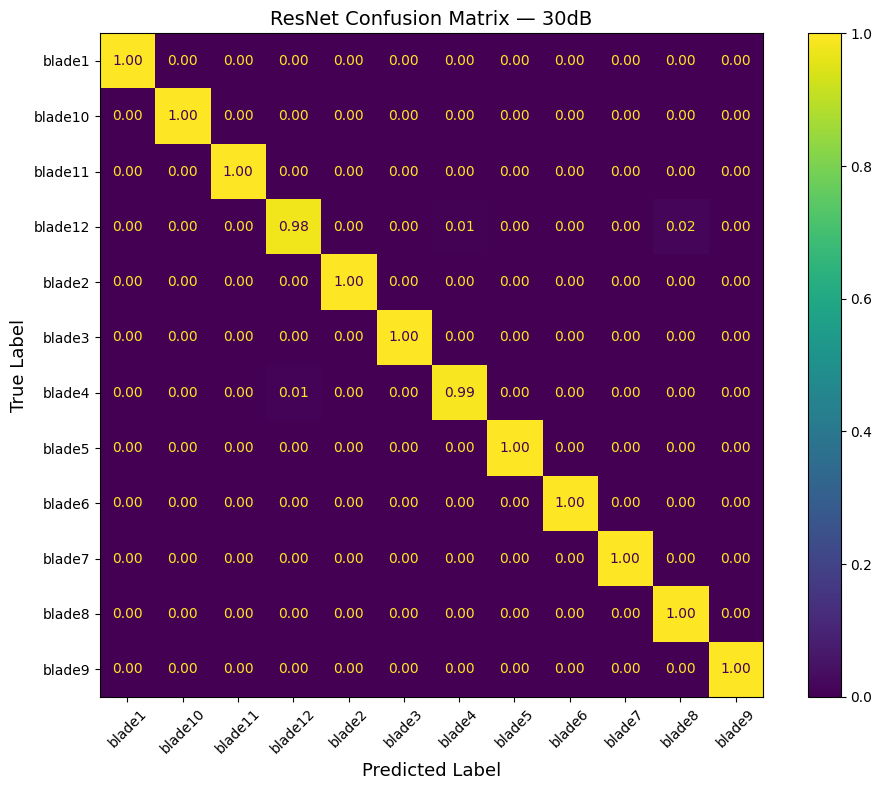

Evaluating: 25dB
  [25dB] MCC: 0.9886 | F1 (macro): 0.9896


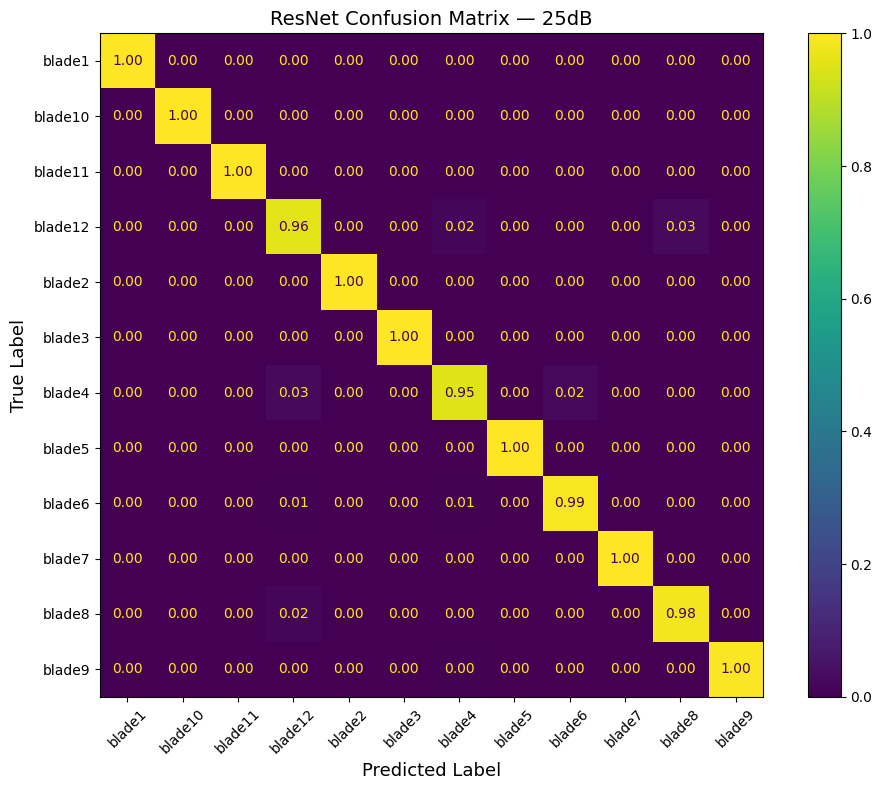

Evaluating: 20dB
  [20dB] MCC: 0.9133 | F1 (macro): 0.9199


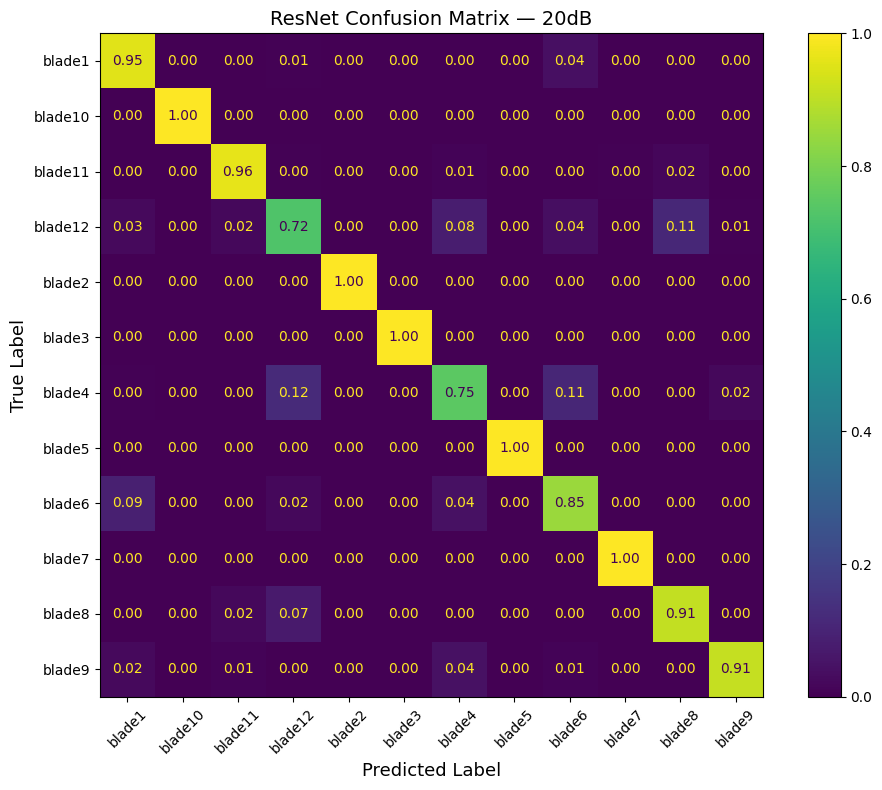

Evaluating: 15dB
  [15dB] MCC: 0.7680 | F1 (macro): 0.7838


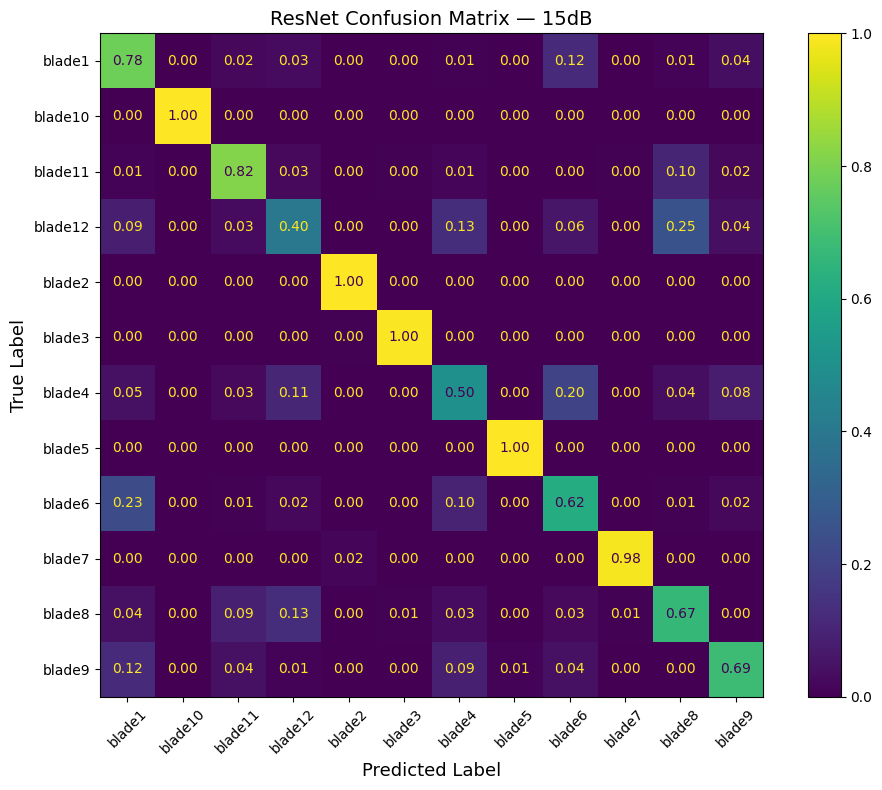

Evaluating: 10dB
  [10dB] MCC: 0.5286 | F1 (macro): 0.5586


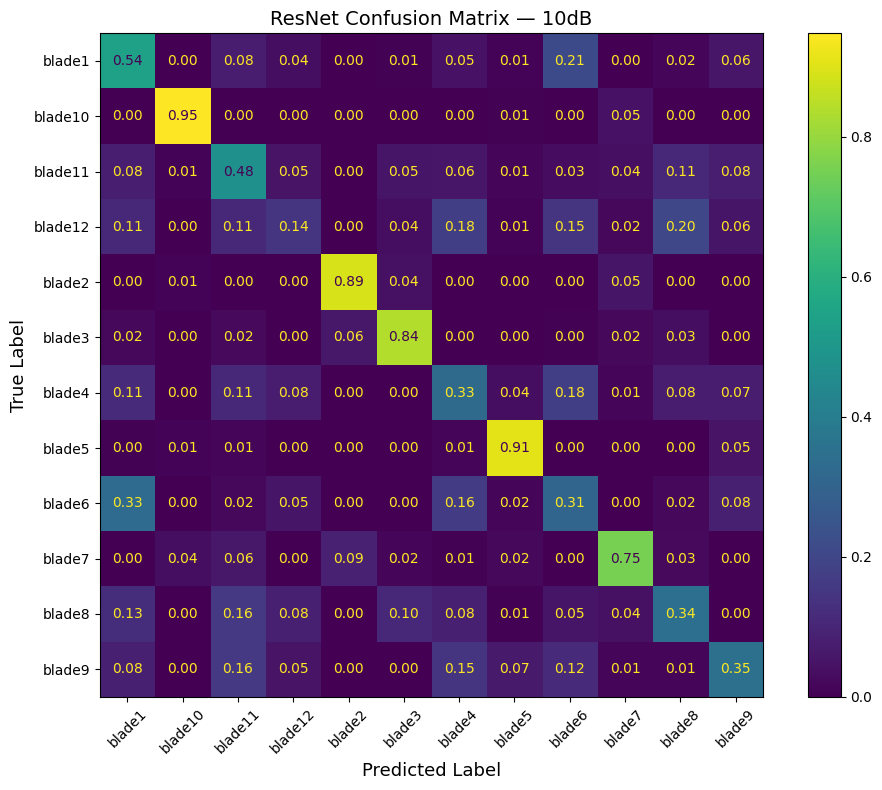

Evaluating: 5dB
  [5dB] MCC: 0.3172 | F1 (macro): 0.3617


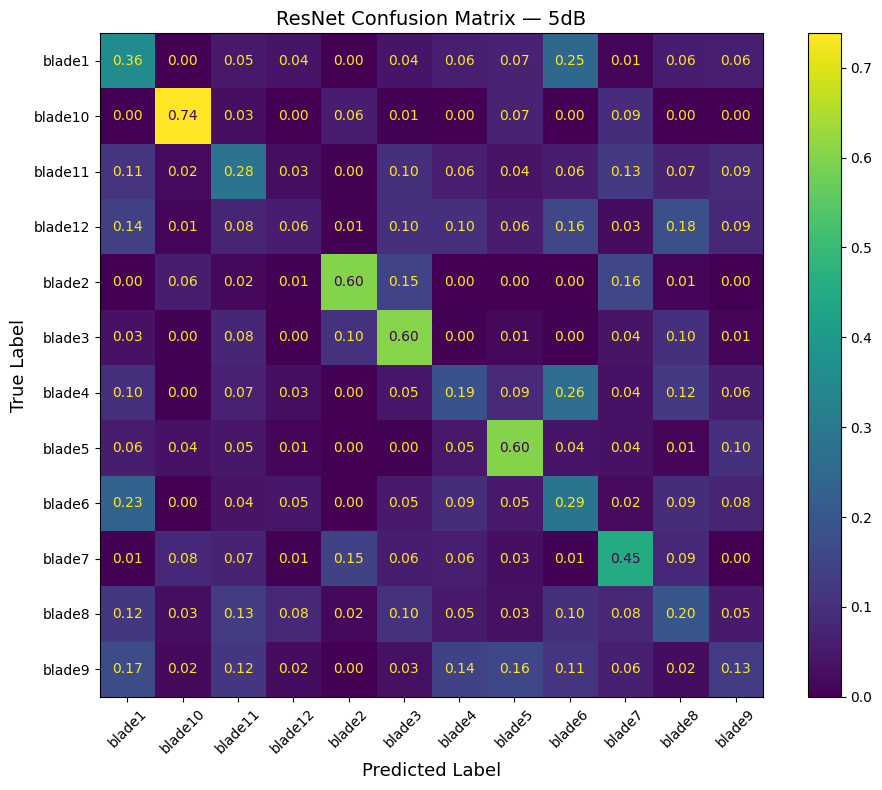

Evaluating: 0dB
  [0dB] MCC: 0.1353 | F1 (macro): 0.1892


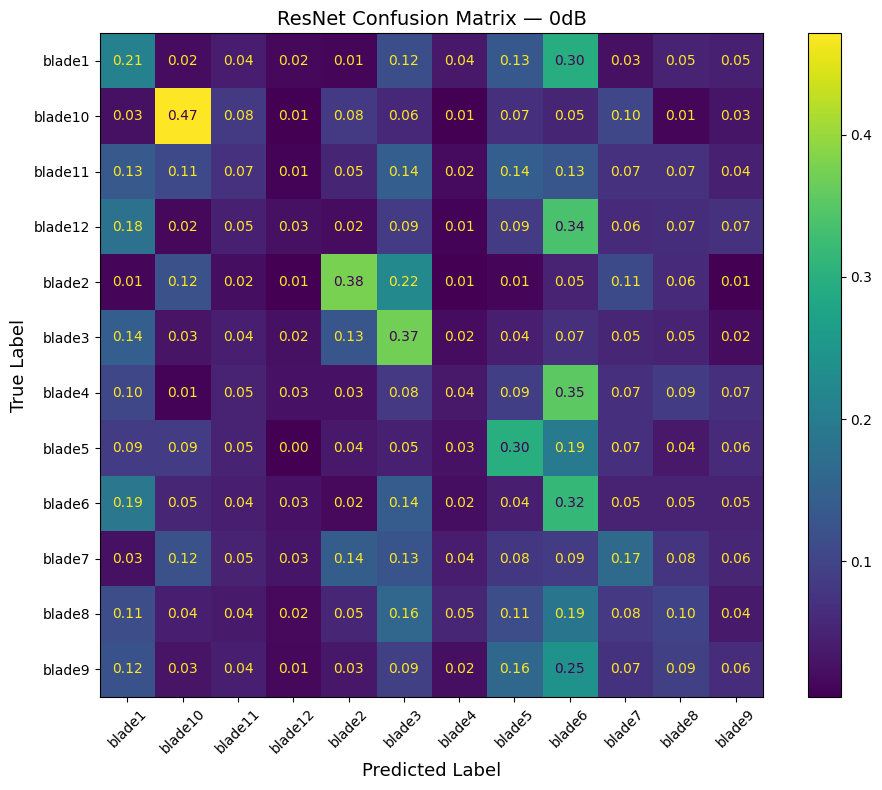

In [13]:
f1_scores = []
for snr in test_SNRs:
    label = f"{snr}dB"
    print(f"Evaluating: {label}")

    eval_dataset = AugmentedPulseDataset(
        base_dataset=test_base,
        target_snrs_db=[snr],
        add_magnitude=True,
        normalise=True,
        return_pdw=False,
        mode="single",
        flatten_pulse=False
    )
    eval_loader = DataLoader(eval_dataset, batch_size=64, shuffle=False)

    y_eval, y_pred = predict(eval_loader)

    _, fone = plot_confusion_matrix(y_eval, y_pred, label)
    f1_scores.append(fone)

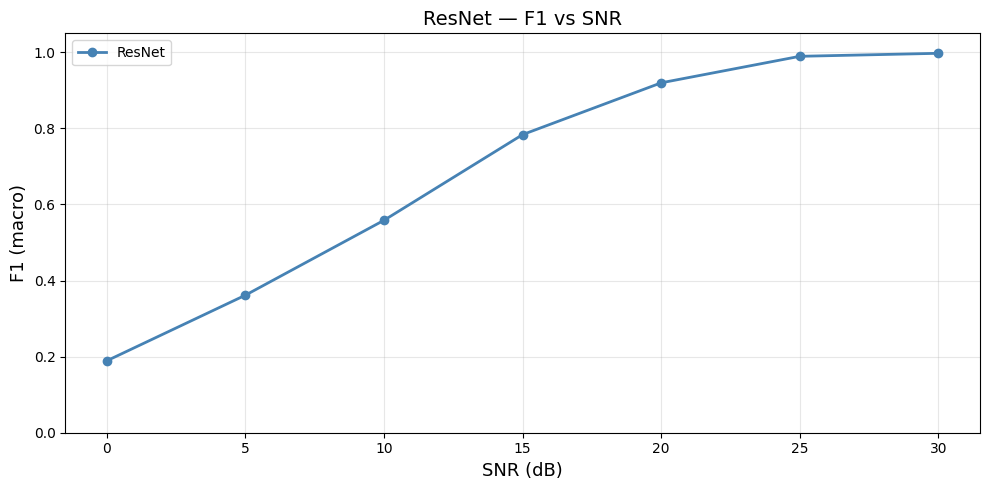

In [14]:
plot_f1_vs_snr(f1_scores, test_SNRs)